# <font color=blue>OPTECH Use Cases: </font> 
## <font color=blue> Use Case 1, Phase 1</font> 
#### Based on paper: X. Liu, B. Wang  and Z. Yang, "Virtual Network Embedding Based on Topology Potential, " Entropy 2018, 20(12), 941.
### `CoDaS`: Erasmus Mundus master's degree in Communications, Engineering and Data Science
### `AI4CI`: Master's degree in Artificial Intelligence for Connected Industries


###  <font color=#922B21>Castelldefels School of Telecommunications and Aerospace Engineering (EETAC)</font>

**<font color=teal>Cristina Cervelló-Pastor (cristina.cervello@upc.edu)</font>**

In [2]:
# Libraries needed
import networkx as nx
import math
import random
import numpy as np
import time
import matplotlib.pyplot as plt

from pyomo.environ import *
from pyomo.opt import SolverFactory
from pyomo.core import Var

import pickle
import sqlite3

## SCENARIO


In [3]:
# Generate the attributes 'location' and 'cpu' of the nodes of a network
def GenerateAttribNetworkNodes( G, minCPU, maxCPU, ):
    distribCPU = np.random.randint( minCPU, maxCPU, len(G.nodes()) ) # distribution of nodes CPU
    for n in list(G.nodes()):
        G.nodes[n]['loc']=(0,0) 
    for n in list(G.nodes()):
        position = False
        l = [G.nodes[n]['loc'] for n in list(G.nodes())]
        while not position:
            x = np.random.randint( minX, maxX, 1)
            y = np.random.randint( minY, maxY, 1)
            if (x,y) not in l:
                G.nodes[n]['loc']=(x,y)
                position = True
        G.nodes[n]['cpu'] = distribCPU[n]


    return G


# Generate the attributes 'distance' and 'bw' of the links of a network
def GenerateAttribNetworkLinks( G, minBW, maxBW ):
    distribBW = np.random.randint( minBW, maxBW, len(G.edges()) ) # distribution of links BW
    for idx, link in enumerate(list(G.edges())):
        G.edges[link]['dist'] = Distance( G.nodes[link[0]]['loc'], G.nodes[link[1]]['loc'] )
        bw = int(round(distribBW[idx]))
        G.edges[(link[0],link[1])]['bw'] = distribBW[idx]
        G.edges[(link[1],link[0])]['bw'] = distribBW[idx]

    return G


# Calculate the distance between two nodes
def Distance(p1, p2):
    return round(math.sqrt((p2[0] - p1[0])**2 + (p2[1] - p1[1])**2),2)

In [4]:
# Location of nodes (physical and virtuals)
minX = 1
maxX= 1000
minY = 1
maxY = 1000

### PHYSICAL NETWORK


In [5]:
NumNodes = 20
Degree = 10

# Nodes CPU
minCPU = 50
maxCPU = 100

# Link BW
minBW= 50
maxBW = 100

def GeneratePhysicalNetwork(): 
    # Generate a random physical network with NumNodes nodes and NumNodes*Degree/2 bidirectional links
    Gp = nx.random_regular_graph( Degree, NumNodes )
    # Fill the nodes and links attributes
    GenerateAttribNetworkNodes( Gp, minCPU, maxCPU )
    GenerateAttribNetworkLinks( Gp, minBW, maxBW )

    # Relabel the number of nodes to start from 1 (instead of 0)
    Gp = nx.convert_node_labels_to_integers(Gp, first_label=1, ordering='sorted', label_attribute=None)

    return Gp
    

/tmp/ipykernel_8116/2473718380.py:35: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  return round(math.sqrt((p2[0] - p1[0])**2 + (p2[1] - p1[1])**2),2)


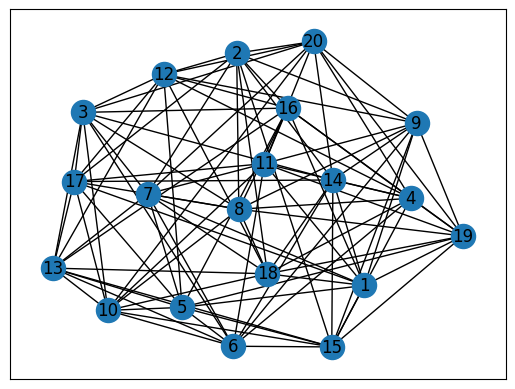

In [6]:
# Physical network
Gp=GeneratePhysicalNetwork()
nx.draw_networkx(Gp)

### VIRTUAL NETWORK

In [7]:
minvCPU = 1
maxvCPU = 50

minvBW= 1
maxvBW = 50

minNumNodesV = 4
maxNumNodesV = 8


Distance_tolerance = 400


def GenerateVirtualNetwork( NumVNodes ):
    degree = (NumVNodes-1)/2
    # Number of nodes x degree has to be an even number
    product =  math.ceil(NumVNodes*degree/2.0) * 2
    # Thus, the degree has to be:
    degree = math.ceil(product/NumVNodes)
    Gv = nx.random_regular_graph( degree, NumVNodes )
    # Fill the nodes and links attributes
    GenerateAttribNetworkNodes( Gv, minvCPU, maxvCPU )
    GenerateAttribNetworkLinks( Gv, minvBW, maxvBW )
    # We will save the physical node where the virtual node is embedded
    for n in list(Gv.nodes()):
        Gv.nodes[n]['PNode'] = 0

    # Relabel the number of nodes to start from 1 (instead of 0)
    Gv=nx.convert_node_labels_to_integers(Gv, first_label=1, ordering='sorted', label_attribute=None)
    
    return Gv
    

/tmp/ipykernel_8116/2473718380.py:35: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  return round(math.sqrt((p2[0] - p1[0])**2 + (p2[1] - p1[1])**2),2)


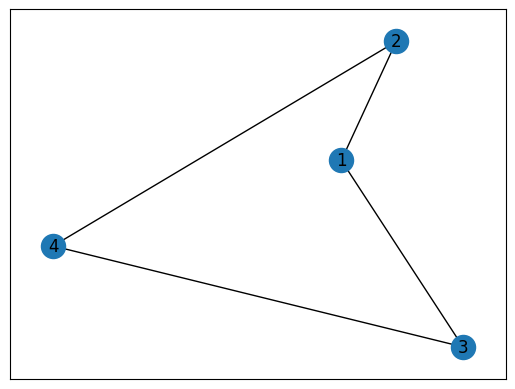

In [8]:
numTotalRequest = 1

VNRarri = 1

distribNumNodes = np.random.randint( minNumNodesV, maxNumNodesV, numTotalRequest )

NumVNodes = distribNumNodes[0]
Gv = GenerateVirtualNetwork(NumVNodes)
nx.draw_networkx(Gv)

## MODEL

## <font color=blue> Note</font> 
##### Use the functions 'nx.get_node_attributes' and 'nx.get_edge_attributes' to get the attributes of nodes and edges of a network. 

##### Example: Returns a dictionary where keys are nodes and values are their CPU capacities
```
nx.get_node_attributes(Gp, 'cpu')
```

In [9]:
nx.get_node_attributes(Gp, 'cpu')

{1: np.int64(91),
 2: np.int64(56),
 3: np.int64(80),
 4: np.int64(88),
 5: np.int64(99),
 6: np.int64(98),
 7: np.int64(66),
 8: np.int64(71),
 9: np.int64(60),
 10: np.int64(52),
 11: np.int64(80),
 12: np.int64(71),
 13: np.int64(88),
 14: np.int64(82),
 15: np.int64(92),
 16: np.int64(53),
 17: np.int64(85),
 18: np.int64(82),
 19: np.int64(94),
 20: np.int64(54)}

In [10]:
nx.get_edge_attributes(Gp, 'bw')

{(1, 15): np.int64(95),
 (1, 17): np.int64(62),
 (1, 19): np.int64(74),
 (1, 5): np.int64(61),
 (1, 14): np.int64(87),
 (1, 7): np.int64(52),
 (1, 16): np.int64(55),
 (1, 9): np.int64(67),
 (1, 18): np.int64(88),
 (1, 11): np.int64(93),
 (2, 16): np.int64(67),
 (2, 9): np.int64(65),
 (2, 18): np.int64(85),
 (2, 20): np.int64(85),
 (2, 15): np.int64(58),
 (2, 8): np.int64(81),
 (2, 17): np.int64(55),
 (2, 12): np.int64(75),
 (2, 14): np.int64(82),
 (2, 7): np.int64(87),
 (3, 12): np.int64(81),
 (3, 14): np.int64(70),
 (3, 7): np.int64(96),
 (3, 16): np.int64(63),
 (3, 20): np.int64(62),
 (3, 13): np.int64(68),
 (3, 6): np.int64(83),
 (3, 8): np.int64(85),
 (3, 17): np.int64(57),
 (3, 10): np.int64(56),
 (4, 14): np.int64(55),
 (4, 16): np.int64(68),
 (4, 18): np.int64(79),
 (4, 11): np.int64(54),
 (4, 20): np.int64(75),
 (4, 6): np.int64(89),
 (4, 15): np.int64(59),
 (4, 8): np.int64(88),
 (4, 19): np.int64(52),
 (4, 12): np.int64(84),
 (5, 10): np.int64(94),
 (5, 19): np.int64(81),
 (5

In [ ]:
# Create a mathematical model (MILP)
model = ConcreteModel()

#################
## Parameters  ##
#################

model.Np = Set(initialize=list(Gp.nodes()))
model.Ep = Set(dimen=2, initialize=list(nx.get_edge_attributes(Gp, 'bw').keys()))

model.Nv = Set(initialize=list(Gv.nodes()))
model.Ev = Set(dimen=2, initialize=list(nx.get_edge_attributes(Gv, 'bw').keys()))

model.cpu_p = Param(model.Np, within=NonNegativeReals, initialize=nx.get_node_attributes(Gp, 'cpu'))
model.cpu_v = Param(model.Nv, within=NonNegativeReals, initialize=nx.get_node_attributes(Gv, 'cpu'))

model.b_p = Param(model.Ep, within=NonNegativeReals, initialize=nx.get_edge_attributes(Gp, 'bw'))
model.b_v = Param(model.Ev, within=NonNegativeReals, initialize=nx.get_edge_attributes(Gv, 'bw'))

model.distance = Param(model.Nv, model.Np, initialize=lambda m, s, i: Distance(Gv.nodes[s]["loc"], Gp.nodes[i]["loc"]))

model.D = Param(initialize=400)


################
## Variables  ##
################

model.x = Var(model.Np, model.Nv, within=Binary, initialize=0)

model.y = Var(model.Ep, model.Ev, within=Binary, initialize=0)

############
## MODEL  ##
############

# OBJECTIVE FUNCTION

def Objective_rule(model):
    node_cost = sum(model.x[i, s] * model.cpu_v[s] for s in model.Nv for i in model.Np)

    link_cost = sum(model.y[i, j, s, t] * model.b_v[s, t] for s, t in model.Ev for i, j in model.Ep)
    
    return node_cost + link_cost

model.objective_cost = Objective(rule=Objective_rule, sense=minimize)

model.objective_cost.activate()

# CONSTRAINTS

# Constraint 1
def CPU_rule(model, s, i):
    return model.x[i, s] * model.cpu_v[s] <= model.cpu_p[i]

model.cpu_constraint = Constraint(model.Nv, model.Np, rule=CPU_rule)

# Constraint 2
def Location_rule(model, s, i):
    return model.x[i, s] * model.distance[s, i] <= model.D

model.location_constraint = Constraint(model.Nv, model.Np, rule=Location_rule)

# Constraint 3
def Physical_node_rule(model, i):
    return sum(model.x[i, s] for s in model.Nv) <= 1

model.physical_node_constraint = Constraint(model.Np, rule=Physical_node_rule)

# Constraint 4
def Virtual_node_rule(model, s):
    return sum(model.x[i, s] for i in model.Np) == 1

model.virtual_node_constraint = Constraint(model.Nv, rule=Virtual_node_rule)

# Constraint 5
def Bandwidth_rule(model, i, j):
    return sum(model.y[i, j, s, t] * model.b_v[s, t] for s, t in model.Ev) <= model.b_p[i, j]

model.bandwidth_constraint = Constraint(model.Ep, rule=Bandwidth_rule)


# Constraint 6
def Flow_rule(model, i, s, t):
    outflow = sum(model.y[u, v, s, t] for u, v in model.Ep if u == i)
    
    inflow = sum(model.y[u, v, s, t] for u, v in model.Ep if v == i)
    
    return outflow - inflow == model.x[i, s] - model.x[i, t]


model.flow_constraint = Constraint(model.Np, model.Ev, rule=Flow_rule)

/tmp/ipykernel_8116/2473718380.py:35: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  return round(math.sqrt((p2[0] - p1[0])**2 + (p2[1] - p1[1])**2),2)


## SOLVE THE MODEL

In [12]:
solver = SolverFactory('glpk')
results=solver.solve(model)

## PRINT RESULTS

In [13]:
if results.solver.termination_condition == TerminationCondition.optimal:
    print("Optimal Solution Found!")

    print("Minimum embedding cost =", value(model.objective_cost))

    print("\nNode mapping:")
    for s in model.Nv:
        for i in model.Np:
            if value(model.x[i, s]) > 0.5:
                print(f"Virtual node {s} -> Physical node {i}")
    
    print("\nLink mapping:")
    for s, t in model.Ev:
        for i, j in model.Ep:
            if value(model.y[i, j, s, t]) > 0.5:
                print(f"Virtual link ({s}, {t}) uses physical link ({i}, {j})"
                )

else:
    print("\nNo optimal solution found.")

Optimal Solution Found!
Minimum embedding cost = 199.0

Node mapping:
Virtual node 1 -> Physical node 2
Virtual node 2 -> Physical node 9
Virtual node 3 -> Physical node 18
Virtual node 4 -> Physical node 20

Link mapping:
Virtual link (1, 2) uses physical link (2, 9)
Virtual link (1, 3) uses physical link (2, 18)
Virtual link (2, 4) uses physical link (9, 20)
Virtual link (3, 4) uses physical link (18, 19)
Virtual link (3, 4) uses physical link (19, 20)
